[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Prasathn01/wattwise-ml/blob/main/notebooks/PBL1_Units1_2.ipynb)

# PBL 1 — Household Energy Consumption Analysis & Peak-Load Prediction
**Course:** 21CSC305P Machine Learning  **Team:** 4  **Units covered:** Unit 1 and Unit 2

**Dataset:** UCI *Individual Household Electric Power Consumption* (ID 235) — one house near Paris (Sceaux), one reading per minute, Dec 2006 – Nov 2010, 2,075,259 rows × 9 columns.
https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption

| Reg. No. | Name |
|---|---|
| RA2411026011138 | Amit Kumar Singh |
| RA2411026011139 | N Ram Prasath |
| RA2411026011140 | G Viswa Deepak Raga |
| RA2411026011141 | Suriya Narayanan S (Team Leader) |
| RA2411026011142 | Sidharth S |

**Unit 1 title:** Probabilistic analysis of minute-level household power usage (active power, voltage, sub-metering)
**Unit 2 title:** Predicting `Global_active_power` with least squares, ridge & Bayesian linear regression; peak vs off-peak hour classification with Bayesian logistic regression & SVM

**Objective.** (1) Describe the household's consumption with probability: distributions, expectations, covariance, conditional probabilities of peak load. (2) Forecast next-hour active power with linear regression models. (3) Classify whether an hour will be a peak-load hour. In both tasks, compare the models listed in the syllabus mapping.

In [1]:
import os, zipfile, urllib.request, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.special import expit

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit
from sklearn.linear_model import (LinearRegression, HuberRegressor, RidgeCV, Ridge,
                                  BayesianRidge, LogisticRegression)
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC, LinearSVC
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, log_loss, brier_score_loss)

warnings.filterwarnings('ignore')
pd.set_option('display.width', 140); pd.set_option('display.max_columns', 20)

# plotting style: thin lines, light grid, one y-axis per chart, fixed colour order
C = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#4a3aa7', '#e34948']
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.color': '#e6e6e3',
                     'grid.linewidth': 0.6, 'axes.edgecolor': '#b5b4ad', 'axes.spines.top': False,
                     'axes.spines.right': False, 'lines.linewidth': 1.8, 'font.size': 9.5,
                     'axes.titlesize': 10.5, 'axes.titleweight': 'bold', 'legend.frameon': False,
                     'axes.prop_cycle': plt.cycler(color=C)})
SEED = 42
print('numpy', np.__version__, '| pandas', pd.__version__)

numpy 2.5.3 | pandas 3.0.5


---
# UNIT 1 — Probabilistic analysis of minute-level household power usage

**Syllabus mapping:** ML – what & why; supervised vs unsupervised view of the data; polynomial curve fitting (hourly consumption curve); discrete RVs, fundamental rules & Bayes rule (P(peak | evening hour)); independence & conditional independence; continuous RVs – quantiles, mean, variance; probability densities, expectation & covariance.
**Practice 1:** import, load & view dataset  **Practice 2:** summary & statistics

## 1.1 ML — what & why; supervised vs unsupervised view of this data
Electricity demand in a home changes by the hour and by the day. A supplier, or a smart-home controller, needs to know **how much power the house will draw next** and **when the high-demand (peak) hours will be**. Fixed rules cannot cover this because usage depends on people's routines. Machine learning lets us estimate these patterns from four years of recorded data.

The same table can be framed in three ways:

| View | What we learn | Target | Unit |
|---|---|---|---|
| Supervised — regression | next-hour `Global_active_power` (kW) | continuous | Unit 2 |
| Supervised — classification | is the hour a **peak** hour (top 25 % of load)? | binary label | Unit 2 |
| Unsupervised | groups of similar daily 24-hour load shapes, with no label | none | Unit 3 (preview below) |

## 1.2 Practice 1 — Import, load & view the dataset
The notebook uses `household_power_consumption.txt` from the current folder. If the file is missing, it downloads the zip from UCI once. Missing readings are stored as `?` in the file.

In [2]:
DATA_FILE = 'household_power_consumption.txt'
if not os.path.exists(DATA_FILE):
    url = 'https://archive.ics.uci.edu/static/public/235/individual+household+electric+power+consumption.zip'
    print('Downloading from UCI ...'); urllib.request.urlretrieve(url, 'hpc.zip')
    zipfile.ZipFile('hpc.zip').extractall('.')

t0 = time.time()
raw = pd.read_csv(DATA_FILE, sep=';', na_values='?', low_memory=False)
print(f'Loaded in {time.time()-t0:.1f}s  ->  shape = {raw.shape}')
raw.head()

Loaded in 1.5s  ->  shape = (2075259, 9)


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [3]:
raw.info()
print('\nLast rows:'); print(raw.tail(3).to_string())

<class 'pandas.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   str    
 1   Time                   str    
 2   Global_active_power    float64
 3   Global_reactive_power  float64
 4   Voltage                float64
 5   Global_intensity       float64
 6   Sub_metering_1         float64
 7   Sub_metering_2         float64
 8   Sub_metering_3         float64
dtypes: float64(7), str(2)
memory usage: 142.5 MB

Last rows:
               Date      Time  Global_active_power  Global_reactive_power  Voltage  Global_intensity  Sub_metering_1  Sub_metering_2  Sub_metering_3
2075256  26/11/2010  21:00:00                0.938                    0.0   239.82               3.8             0.0             0.0             0.0
2075257  26/11/2010  21:01:00                0.934                    0.0   239.70               3.8             0.0             0.0           

**Columns.** `Global_active_power` (kW, minute average: the power actually consumed), `Global_reactive_power` (kW), `Voltage` (V), `Global_intensity` (A), and three sub-meters in watt-hours per minute: `Sub_metering_1` = kitchen (dishwasher, oven, microwave), `Sub_metering_2` = laundry (washing machine, dryer, fridge, light), `Sub_metering_3` = electric water heater + air conditioner.

In [4]:
df = raw.copy()
df['datetime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'], format='%d/%m/%Y %H:%M:%S')
df = df.drop(columns=['Date', 'Time']).set_index('datetime').sort_index()
NUM = ['Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity',
       'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']
print('Time span :', df.index.min(), '->', df.index.max())
print('Expected minutes in span:', int((df.index.max() - df.index.min()).total_seconds() // 60) + 1,
      '| rows present:', len(df), '| duplicate timestamps:', df.index.duplicated().sum())
df.head()

Time span : 2006-12-16 17:24:00 -> 2010-11-26 21:02:00
Expected minutes in span: 2075259 | rows present: 2075259 | duplicate timestamps: 0


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
datetime,,,,,,,
2006-12-16 17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
2006-12-16 17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2006-12-16 17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
2006-12-16 17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
2006-12-16 17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


## 1.3 Practice 2 — Summary statistics and missing values

In [5]:
summary = df[NUM].describe(percentiles=[.05, .25, .5, .75, .95]).T
summary['skew'] = df[NUM].skew(); summary['kurtosis'] = df[NUM].kurt()
summary.round(3)

,count,mean,std,min,5%,25%,50%,75%,95%,max,skew,kurtosis
Global_active_power,2049280.0,1.092,1.057,0.076,0.184,0.308,0.602,1.528,3.264,11.122,1.786,4.219
Global_reactive_power,2049280.0,0.124,0.113,0.000,0.000,0.048,0.100,0.194,0.338,1.390,1.262,2.606
Voltage,2049280.0,240.840,3.240,223.200,235.120,238.990,241.010,242.890,245.940,254.150,-0.327,0.725
Global_intensity,2049280.0,4.628,4.444,0.200,0.800,1.400,2.600,6.400,13.800,48.400,1.849,4.601
Sub_metering_1,2049280.0,1.122,6.153,0.000,0.000,0.000,0.000,0.000,1.000,88.000,5.945,35.643
Sub_metering_2,2049280.0,1.299,5.822,0.000,0.000,0.000,0.000,1.000,2.000,80.000,7.091,57.907
Sub_metering_3,2049280.0,6.458,8.437,0.000,0.000,0.000,1.000,17.000,19.000,31.000,0.725,-1.282


Missing rows: 25,979 of 2,075,259 (1.25 %)
Rows where only some columns are missing: 0
Number of gaps: 71 | longest gap: 7226 min (5.0 days) | gaps longer than 1 hour: 9


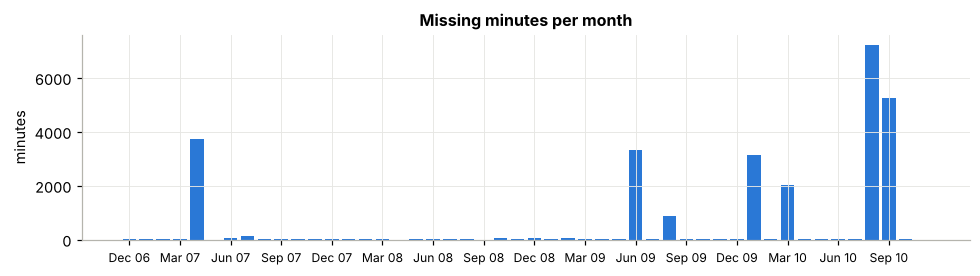

In [6]:
miss = df['Global_active_power'].isna()
print(f'Missing rows: {miss.sum():,} of {len(df):,} ({miss.mean()*100:.2f} %)')
print('Rows where only some columns are missing:', (df[NUM].isna().any(axis=1) & ~df[NUM].isna().all(axis=1)).sum())

# contiguous runs of missing minutes
run_id = (miss != miss.shift()).cumsum()
runs = miss.groupby(run_id).agg(['first', 'size'])
runs = runs[runs['first']]['size']
print(f'Number of gaps: {len(runs)} | longest gap: {runs.max()} min ({runs.max()/1440:.1f} days) | '
      f'gaps longer than 1 hour: {(runs > 60).sum()}')

mm = miss.resample('MS').sum()
fig, ax = plt.subplots(figsize=(9, 2.6))
ax.bar(range(len(mm)), mm.values, color=C[0], width=0.8)
ax.set_xticks(range(0, len(mm), 3)); ax.set_xticklabels([mm.index[i].strftime('%b %y') for i in range(0, len(mm), 3)], fontsize=8)
ax.set_title('Missing minutes per month'); ax.set_ylabel('minutes')
plt.tight_layout(); plt.show()

**Preprocessing decisions.**
1. Missing values are whole rows (every column is missing together) in 71 gaps, so we do **not** impute minute readings. Minute-level statistics use the 2,049,280 complete rows.
2. For modelling we **resample to hourly means**. An hour with some missing minutes is averaged over the minutes present. Gaps of up to 3 whole hours are filled by time interpolation. Longer gaps (multi-day outages) stay missing, and those rows are dropped after features are built, so no long gap is invented.
3. A derived variable, `Sub_metering_other` = `Global_active_power`×1000/60 − (SM1+SM2+SM3), is the energy (Wh/min) used by appliances not covered by any sub-meter.

In [7]:
d = df.dropna().copy()                                    # complete minute rows
d['Sub_metering_other'] = d['Global_active_power'] * 1000 / 60 - d[['Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']].sum(axis=1)

hourly = df.resample('h').mean()
n_empty = hourly['Global_active_power'].isna().sum()
hourly = hourly.interpolate(method='time', limit=3, limit_area='inside')
print(f'Hourly rows: {len(hourly):,} | fully-empty hours: {n_empty} | still missing after <=3h interpolation: '
      f'{hourly["Global_active_power"].isna().sum()}')
hourly['hour'] = hourly.index.hour
hourly['dow'] = hourly.index.dayofweek
hourly['weekend'] = (hourly['dow'] >= 5).astype(int)
H = hourly.dropna(subset=['Global_active_power']).copy()   # hourly table used in Unit 1
H.head()

Hourly rows: 34,589 | fully-empty hours: 421 | still missing after <=3h interpolation: 399


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,hour,dow,weekend
datetime,,,,,,,,,,
2006-12-16 17:00:00,4.222889,0.229000,234.643889,18.100000,0.0,0.527778,16.861111,17,5,1
2006-12-16 18:00:00,3.632200,0.080033,234.580167,15.600000,0.0,6.716667,16.866667,18,5,1
2006-12-16 19:00:00,3.400233,0.085233,233.232500,14.503333,0.0,1.433333,16.683333,19,5,1
2006-12-16 20:00:00,3.268567,0.075100,234.071500,13.916667,0.0,0.000000,16.783333,20,5,1
2006-12-16 21:00:00,3.056467,0.076667,237.158667,13.046667,0.0,0.416667,17.216667,21,5,1


## 1.4 Exploratory data analysis

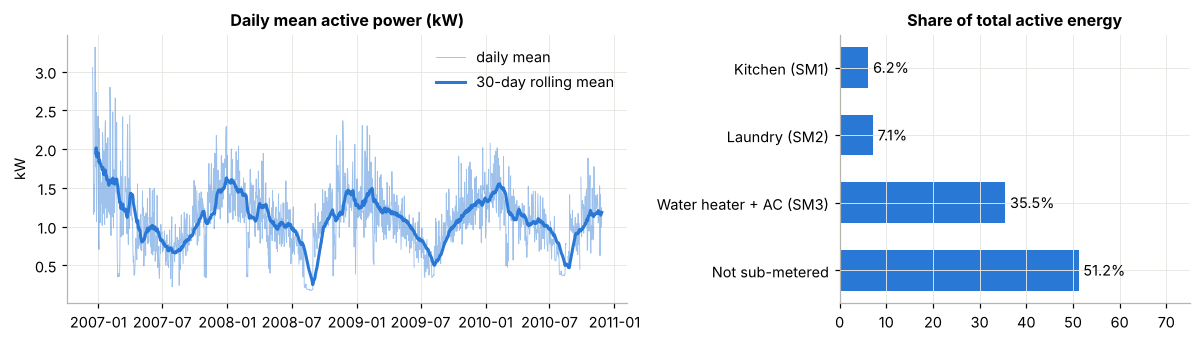

Mean kW by calendar month: {1: 1.46, 2: 1.3, 3: 1.23, 4: 1.05, 5: 1.03, 6: 0.91, 7: 0.7, 8: 0.57, 9: 0.98, 10: 1.14, 11: 1.29, 12: 1.49}


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), gridspec_kw={'width_ratios': [1.6, 1]})
daily = df['Global_active_power'].resample('D').mean()
axes[0].plot(daily.index, daily, color=C[0], lw=0.6, alpha=0.45, label='daily mean')
axes[0].plot(daily.index, daily.rolling(30, min_periods=10).mean(), color=C[0], lw=2, label='30-day rolling mean')
axes[0].set_title('Daily mean active power (kW)'); axes[0].set_ylabel('kW'); axes[0].legend(loc='upper right')

parts = d[['Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3', 'Sub_metering_other']].sum()
share = (parts / parts.sum() * 100).rename({'Sub_metering_1': 'Kitchen (SM1)', 'Sub_metering_2': 'Laundry (SM2)',
                                           'Sub_metering_3': 'Water heater + AC (SM3)', 'Sub_metering_other': 'Not sub-metered'})
axes[1].barh(share.index, share.values, color=C[0], height=0.6)
for i, v in enumerate(share.values): axes[1].text(v + 1, i, f'{v:.1f}%', va='center')
axes[1].set_title('Share of total active energy'); axes[1].set_xlim(0, 75); axes[1].invert_yaxis()
plt.tight_layout(); plt.show()

monthly = df['Global_active_power'].groupby(df.index.month).mean()
print('Mean kW by calendar month:', monthly.round(2).to_dict())

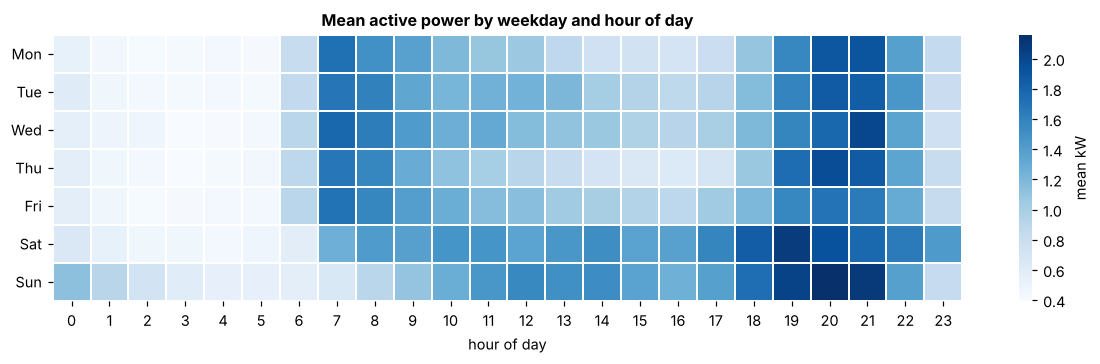

In [9]:
heat = H.pivot_table(index='dow', columns='hour', values='Global_active_power', aggfunc='mean')
heat.index = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
fig, ax = plt.subplots(figsize=(11, 3.4))
sns.heatmap(heat, cmap='Blues', ax=ax, cbar_kws={'label': 'mean kW'}, linewidths=0.3, linecolor='white')
ax.set_title('Mean active power by weekday and hour of day'); ax.set_xlabel('hour of day'); ax.set_ylabel('')
ax.tick_params(axis='y', rotation=0); ax.grid(False)
plt.tight_layout(); plt.show()

**Unsupervised view (preview of Unit 3).** Each day is a 24-value load curve. With no labels, 60 random days already show a few repeating shapes (morning peak, evening peak, flat or away days). Unit 3 will cluster these curves.

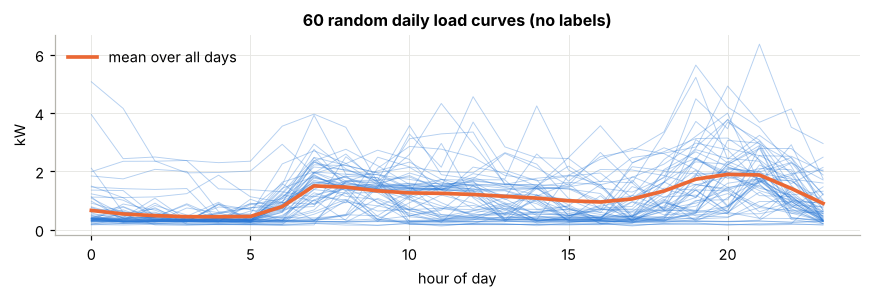

Complete days available: 1419


In [10]:
piv = H.assign(date=H.index.normalize()).pivot_table(index='date', columns='hour', values='Global_active_power')
piv = piv.dropna()
sample_days = piv.sample(60, random_state=SEED)
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.plot(range(24), sample_days.T.values, color=C[0], lw=0.6, alpha=0.35)
ax.plot(range(24), piv.mean().values, color=C[1], lw=2.4, label='mean over all days')
ax.set_title('60 random daily load curves (no labels)'); ax.set_xlabel('hour of day'); ax.set_ylabel('kW'); ax.legend()
plt.tight_layout(); plt.show()
print('Complete days available:', len(piv))

## 1.5 Continuous random variables — quantiles, mean, variance and densities
Treat a randomly chosen minute's active power $X$ and voltage $V$ as continuous random variables and estimate their distributions from the 2.05 M complete readings.

In [11]:
qs = [0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
tab = pd.DataFrame({c: d[c].quantile(qs) for c in ['Global_active_power', 'Voltage', 'Global_intensity']}).T
tab.columns = [f'Q{int(q*100)}' for q in qs]
tab['mean'] = d[['Global_active_power', 'Voltage', 'Global_intensity']].mean()
tab['variance'] = d[['Global_active_power', 'Voltage', 'Global_intensity']].var()
tab['std'] = np.sqrt(tab['variance']); tab['IQR'] = tab['Q75'] - tab['Q25']
tab.round(3)

,Q1,Q5,Q25,Q50,Q75,Q95,Q99,mean,variance,std,IQR
Global_active_power,0.11,0.184,0.308,0.602,1.528,3.264,4.85,1.092,1.118,1.057,1.22
Voltage,232.14,235.120,238.990,241.010,242.890,245.940,248.27,240.840,10.498,3.240,3.90
Global_intensity,0.60,0.800,1.400,2.600,6.400,13.800,20.60,4.628,19.753,4.444,5.00


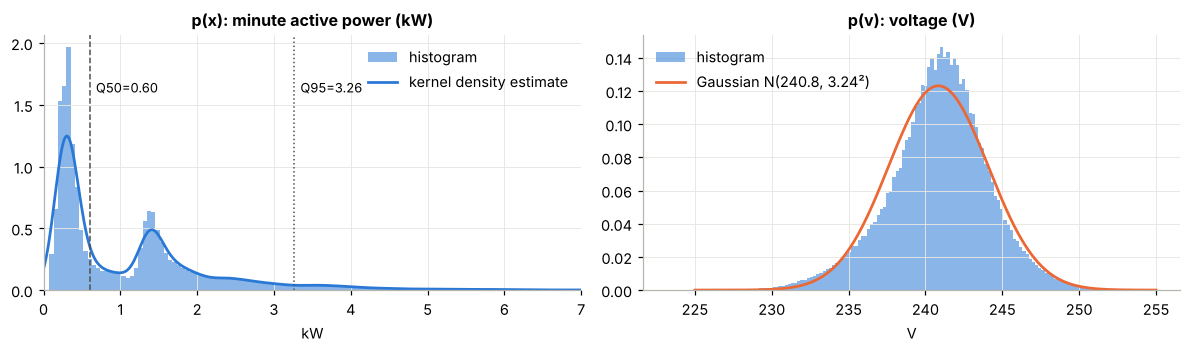

Active power: mean=1.092, median=0.602, skew=1.79  -> right-skewed, mean > median


Voltage     : mean=240.84, sd=3.24, skew=-0.33, excess kurtosis=0.72
P(|V-mean| < 2 sd) = 0.9453   (Gaussian would give 0.9545)
P(X > 3 kW) = 0.0613   P(X < 0.5 kW) = 0.4665


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
x = d['Global_active_power']
axes[0].hist(x, bins=200, density=True, color=C[0], alpha=0.55, label='histogram')
kde = stats.gaussian_kde(x.sample(60000, random_state=SEED)); g = np.linspace(0, 7, 400)
axes[0].plot(g, kde(g), color=C[0], label='kernel density estimate')
for q, ls in [(0.5, '--'), (0.95, ':')]:
    axes[0].axvline(x.quantile(q), color='#52514e', ls=ls, lw=1); axes[0].text(x.quantile(q) + 0.08, 1.6, f'Q{int(q*100)}={x.quantile(q):.2f}', fontsize=8.5)
axes[0].set_xlim(0, 7); axes[0].set_title('p(x): minute active power (kW)'); axes[0].set_xlabel('kW'); axes[0].legend(loc='upper right')

v = d['Voltage']; mu, sd = v.mean(), v.std(); gv = np.linspace(225, 255, 400)
axes[1].hist(v, bins=150, density=True, color=C[0], alpha=0.55, label='histogram')
axes[1].plot(gv, stats.norm.pdf(gv, mu, sd), color=C[1], label=f'Gaussian N({mu:.1f}, {sd:.2f}²)')
axes[1].set_title('p(v): voltage (V)'); axes[1].set_xlabel('V'); axes[1].legend(loc='upper left')
plt.tight_layout(); plt.show()

print(f'Active power: mean={x.mean():.3f}, median={x.median():.3f}, skew={stats.skew(x):.2f}  -> right-skewed, mean > median')
print(f'Voltage     : mean={mu:.2f}, sd={sd:.2f}, skew={stats.skew(v):.2f}, excess kurtosis={stats.kurtosis(v):.2f}')
inside = ((v > mu - 2*sd) & (v < mu + 2*sd)).mean()
print(f'P(|V-mean| < 2 sd) = {inside:.4f}   (Gaussian would give 0.9545)')
print(f'P(X > 3 kW) = {(x > 3).mean():.4f}   P(X < 0.5 kW) = {(x < 0.5).mean():.4f}')

## 1.6 Expectation and covariance

E[X] (hourly data)          = 1.0916 kW
sum_h P(h) * E[X | hour=h]  = 1.0916 kW   (law of total expectation)
E[X | weekend] = 1.233 kW,  E[X | weekday] = 1.036 kW


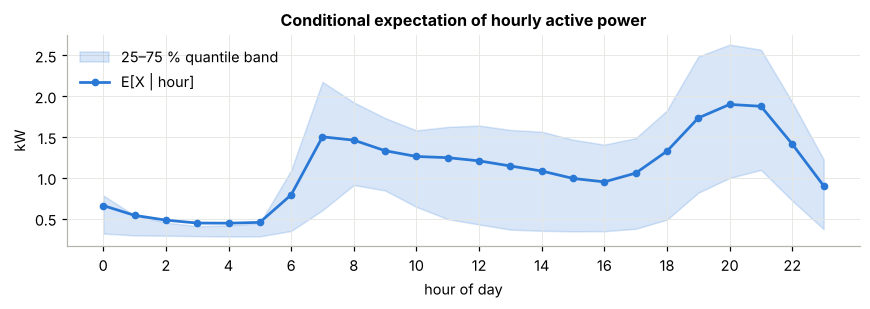

In [13]:
# conditional expectation E[X | hour] and the law of total expectation
EXh = H.groupby('hour')['Global_active_power'].agg(['mean', 'std', lambda s: s.quantile(.25), lambda s: s.quantile(.75)])
EXh.columns = ['mean', 'std', 'q25', 'q75']
Ph = H['hour'].value_counts(normalize=True).sort_index()
print(f'E[X] (hourly data)          = {H["Global_active_power"].mean():.4f} kW')
print(f'sum_h P(h) * E[X | hour=h]  = {(Ph * EXh["mean"]).sum():.4f} kW   (law of total expectation)')
print(f'E[X | weekend] = {H.loc[H.weekend==1, "Global_active_power"].mean():.3f} kW,  '
      f'E[X | weekday] = {H.loc[H.weekend==0, "Global_active_power"].mean():.3f} kW')

fig, ax = plt.subplots(figsize=(8, 2.9))
ax.fill_between(EXh.index, EXh['q25'], EXh['q75'], color=C[0], alpha=0.18, label='25–75 % quantile band')
ax.plot(EXh.index, EXh['mean'], color=C[0], marker='o', ms=4, label='E[X | hour]')
ax.set_title('Conditional expectation of hourly active power'); ax.set_xlabel('hour of day'); ax.set_ylabel('kW')
ax.set_xticks(range(0, 24, 2)); ax.legend(loc='upper left'); plt.tight_layout(); plt.show()

Covariance matrix (minute data):
                       Global_active_power  Global_reactive_power  Voltage  Global_intensity  Sub_metering_1  Sub_metering_2  Sub_metering_3
Global_active_power                  1.118                  0.029   -1.369             4.694           3.151           2.675           5.696
Global_reactive_power                0.029                  0.013   -0.041             0.133           0.085           0.091           0.085
Voltage                             -1.369                 -0.041   10.498            -5.924          -3.907          -3.158          -7.331
Global_intensity                     4.694                  0.133   -5.924            19.753          13.381          11.394          23.494
Sub_metering_1                       3.151                  0.085   -3.907            13.381          37.860           1.960           5.325
Sub_metering_2                       2.675                  0.091   -3.158            11.394           1.960          33.

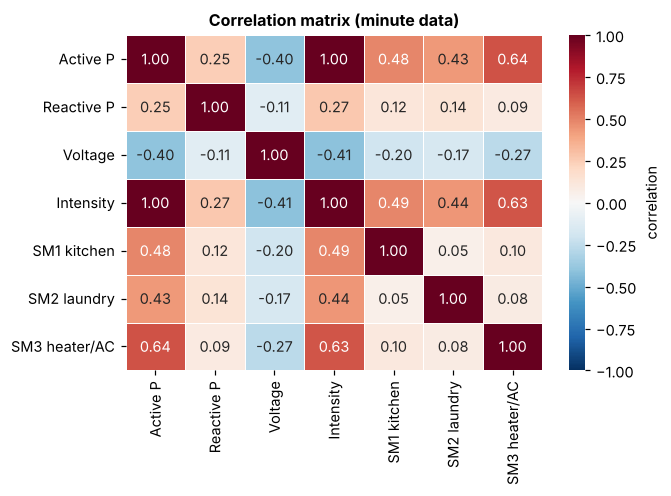

In [14]:
cov = d[NUM].cov(); corr = d[NUM].corr()
print('Covariance matrix (minute data):'); print(cov.round(3).to_string())
short = ['Active P', 'Reactive P', 'Voltage', 'Intensity', 'SM1 kitchen', 'SM2 laundry', 'SM3 heater/AC']
fig, ax = plt.subplots(figsize=(6.2, 4.6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, center=0, ax=ax,
            xticklabels=short, yticklabels=short, linewidths=0.4, linecolor='white', cbar_kws={'label': 'correlation'})
ax.grid(False); ax.set_title('Correlation matrix (minute data)'); plt.tight_layout(); plt.show()

In [15]:
# Physics check: active power P = V * I * power-factor
pf = d['Global_active_power'] * 1000 / (d['Voltage'] * d['Global_intensity'])
print(f'corr(Active power, Intensity) = {corr.loc["Global_active_power", "Global_intensity"]:.4f}')
print(f'Implied power factor P/(V*I): median = {pf.median():.3f}, 1st-99th percentile = {pf.quantile(.01):.3f}-{pf.quantile(.99):.3f}')
print(f'Cov(Active power, Voltage) = {cov.loc["Global_active_power", "Voltage"]:.3f}  (corr {corr.loc["Global_active_power", "Voltage"]:.2f})')

corr(Active power, Intensity) = 0.9989
Implied power factor P/(V*I): median = 0.992, 1st-99th percentile = 0.753-1.131
Cov(Active power, Voltage) = -1.369  (corr -0.40)


**Why this matters for Unit 2.** `Global_intensity` is the current, and active power ≈ voltage × current × power factor (median power factor ≈ 0.99). Predicting active power from same-minute intensity would therefore give R² ≈ 1 without learning anything useful; it is **target leakage**. In Unit 2 we only use information available **before** the hour being predicted.
The negative covariance between power and voltage is also physical: when the house draws more current, the supply voltage at the meter drops a little.

## 1.7 Polynomial curve fitting — the hourly consumption curve
We fit $y(x,\mathbf w)=\sum_{j=0}^{M} w_j x^j$ to an hourly consumption curve by least squares (minimising the sum-of-squares error), with hour rescaled to $x\in[-1,1]$.

* **Training curve:** the hourly mean of only **5 randomly chosen days** from 2006–2009, a small and noisy sample.
* **Test curve:** the true long-run hourly mean curve for **2010** (unseen year).

Repeating this for 200 random 5-day samples gives average training and test $E_{RMS}$ for each order $M$. We then add an L2 penalty $\lambda\lVert\mathbf w\rVert^2$ (regularised least squares) to the high-order model.

In [16]:
xh = np.linspace(-1, 1, 24)
def poly_fit(x, t, M, lam=0.0):
    Phi = np.vander(x, M + 1, increasing=True)
    return np.linalg.solve(Phi.T @ Phi + lam * np.eye(M + 1), Phi.T @ t)
def poly_pred(w, x): return np.vander(x, len(w), increasing=True) @ w
rms = lambda a, b: np.sqrt(np.mean((a - b) ** 2))

train_pool = piv.loc[:'2009-12-31']; t_test = piv.loc['2010'].mean().values
Ms = list(range(0, 17)); lams = 10.0 ** np.arange(-8, 1)
rng = np.random.default_rng(SEED); R = 200
Etr = np.zeros(len(Ms)); Ete = np.zeros(len(Ms)); Rtr = np.zeros(len(lams)); Rte = np.zeros(len(lams))
for r in range(R):
    t_tr = train_pool.loc[rng.choice(train_pool.index, 5, replace=False)].mean().values
    if r == 0: t_example = t_tr
    for i, M in enumerate(Ms):
        w = poly_fit(xh, t_tr, M); Etr[i] += rms(poly_pred(w, xh), t_tr); Ete[i] += rms(poly_pred(w, xh), t_test)
    for j, l in enumerate(lams):
        w = poly_fit(xh, t_tr, 16, l); Rtr[j] += rms(poly_pred(w, xh), t_tr); Rte[j] += rms(poly_pred(w, xh), t_test)
Etr /= R; Ete /= R; Rtr /= R; Rte /= R
poly_table = pd.DataFrame({'M': Ms, 'E_RMS train': Etr, 'E_RMS test': Ete}).set_index('M')
print(poly_table.T.round(3).to_string())
best_M = int(poly_table['E_RMS test'].idxmin()); best_l = lams[np.argmin(Rte)]
print(f'\nBest unregularised order M = {best_M} (test E_RMS {Ete.min():.3f});  M = 16 test E_RMS = {Ete[-1]:.3f}')
print(f'M = 16 with lambda = {best_l:.0e}: test E_RMS = {Rte.min():.3f}  (best overall)')

M               0      1      2      3      4      5      6      7      8      9      10     11     12     13     14     15     16
E_RMS train  0.535  0.420  0.398  0.386  0.377  0.256  0.231  0.214  0.202  0.190  0.170  0.153  0.145  0.130  0.120  0.112  0.095
E_RMS test   0.428  0.371  0.364  0.377  0.386  0.331  0.326  0.326  0.334  0.337  0.336  0.337  0.340  0.341  0.343  0.346  0.347

Best unregularised order M = 6 (test E_RMS 0.326);  M = 16 test E_RMS = 0.347
M = 16 with lambda = 1e-02: test E_RMS = 0.318  (best overall)


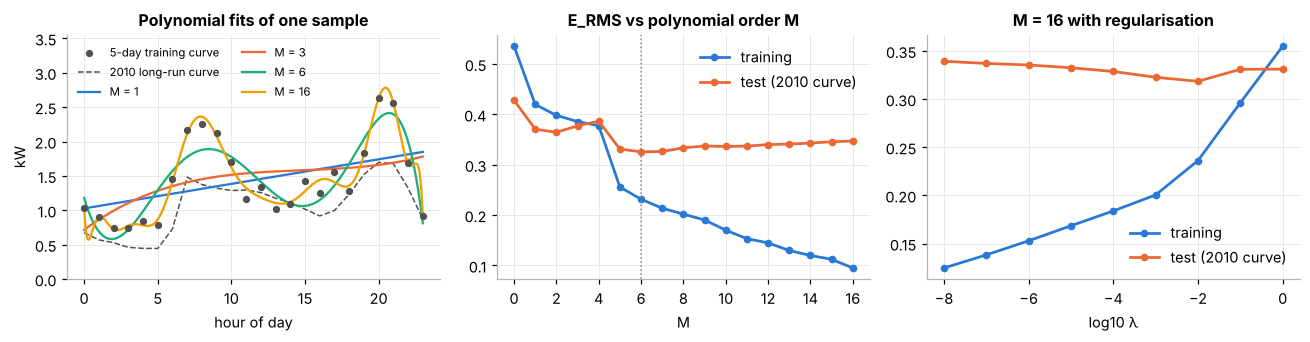

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
xf = np.linspace(-1, 1, 300); hf = (xf + 1) * 11.5
axes[0].scatter(range(24), t_example, color='#52514e', s=14, zorder=3, label='5-day training curve')
axes[0].plot(range(24), t_test, color='#52514e', lw=1, ls='--', label='2010 long-run curve')
for k, M in enumerate([1, 3, 6, 16]):
    axes[0].plot(hf, poly_pred(poly_fit(xh, t_example, M), xf), color=C[k], lw=1.5, label=f'M = {M}')
axes[0].set_ylim(0, max(t_example.max(), t_test.max()) * 1.35); axes[0].set_title('Polynomial fits of one sample')
axes[0].set_xlabel('hour of day'); axes[0].set_ylabel('kW'); axes[0].legend(fontsize=7.5, ncol=2, loc='upper left')

axes[1].plot(Ms, Etr, color=C[0], marker='o', ms=4, label='training')
axes[1].plot(Ms, Ete, color=C[1], marker='o', ms=4, label='test (2010 curve)')
axes[1].axvline(best_M, color='#8a8984', ls=':', lw=1)
axes[1].set_title('E_RMS vs polynomial order M'); axes[1].set_xlabel('M'); axes[1].set_xticks(range(0, 17, 2)); axes[1].legend()

axes[2].plot(np.log10(lams), Rtr, color=C[0], marker='o', ms=4, label='training')
axes[2].plot(np.log10(lams), Rte, color=C[1], marker='o', ms=4, label='test (2010 curve)')
axes[2].set_title('M = 16 with regularisation'); axes[2].set_xlabel('log10 λ'); axes[2].legend()
plt.tight_layout(); plt.show()

## 1.8 Discrete random variables, sum & product rules, and Bayes' rule: P(peak | evening)
Define two discrete random variables on each hour:
* **Peak** $\in\{0,1\}$: 1 if the hourly mean power ≥ $\tau$, where $\tau$ is the **75th percentile** of hourly power in the training years 2006–2009. The same threshold is used for the Unit 2 classifier.
* **Band** $\in$ {night 0–5, morning 6–11, afternoon 12–17, evening 18–23}. For Bayes' rule we use **Evening** = hours 18:00–22:59.

In [18]:
tau = hourly.loc[:'2009-12-31', 'Global_active_power'].quantile(0.75)
H['peak'] = (H['Global_active_power'] >= tau).astype(int)
H['band'] = pd.cut(H['hour'], [-1, 5, 11, 17, 23], labels=['night', 'morning', 'afternoon', 'evening'])
H['evening'] = H['hour'].between(18, 22).astype(int)
print(f'Peak threshold tau = {tau:.3f} kW')

joint = pd.crosstab(H['peak'], H['band'], normalize='all')
print('\nJoint distribution P(Peak, Band):'); print(joint.round(4).to_string())
print(f'\nSum rule:     P(peak=1) = sum over bands P(peak=1, band) = {joint.loc[1].sum():.4f}  (direct: {H.peak.mean():.4f})')
pe = H.loc[H.band == 'evening', 'peak'].mean()
print(f'Product rule: P(peak=1, evening band) = P(peak=1 | evening band) * P(evening band) = '
      f'{pe:.4f} x {(H.band == "evening").mean():.4f} = {pe * (H.band == "evening").mean():.4f}  (table: {joint.loc[1, "evening"]:.4f})')

Peak threshold tau = 1.596 kW

Joint distribution P(Peak, Band):
band   night  morning  afternoon  evening
peak                                     
0     0.2418   0.1745     0.1934   0.1455
1     0.0084   0.0751     0.0564   0.1049

Sum rule:     P(peak=1) = sum over bands P(peak=1, band) = 0.2448  (direct: 0.2448)
Product rule: P(peak=1, evening band) = P(peak=1 | evening band) * P(evening band) = 0.4188 x 0.2504 = 0.1049  (table: 0.1049)


P(peak)  [prior]                     0.2448
P(evening)                           0.2086
P(evening | peak)  [likelihood]      0.4028
P(peak | evening)  via Bayes rule    0.4726
P(peak | evening)  direct count      0.4726
P(peak | not evening)                0.1847

Evening raises the probability of a peak hour by a factor of 1.93


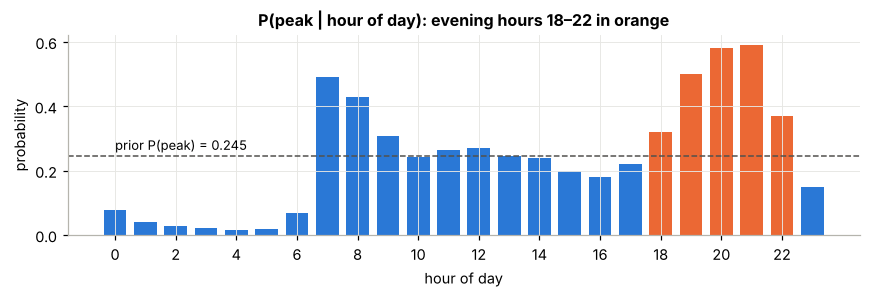

In [19]:
P_peak = H['peak'].mean(); P_eve = H['evening'].mean()
P_eve_given_peak = H.loc[H.peak == 1, 'evening'].mean()
P_peak_given_eve_bayes = P_eve_given_peak * P_peak / P_eve
P_peak_given_eve_direct = H.loc[H.evening == 1, 'peak'].mean()
bayes = pd.Series({'P(peak)  [prior]': P_peak, 'P(evening)': P_eve, 'P(evening | peak)  [likelihood]': P_eve_given_peak,
                   'P(peak | evening)  via Bayes rule': P_peak_given_eve_bayes,
                   'P(peak | evening)  direct count': P_peak_given_eve_direct,
                   'P(peak | not evening)': H.loc[H.evening == 0, 'peak'].mean()})
print(bayes.round(4).to_string())
print(f'\nEvening raises the probability of a peak hour by a factor of {P_peak_given_eve_bayes / P_peak:.2f}')

pk_h = H.groupby('hour')['peak'].mean()
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.bar(pk_h.index, pk_h.values, color=[C[1] if 18 <= h <= 22 else C[0] for h in pk_h.index], width=0.75)
ax.axhline(P_peak, color='#52514e', ls='--', lw=1); ax.text(0, P_peak + 0.02, f'prior P(peak) = {P_peak:.3f}', fontsize=8.5)
ax.set_title('P(peak | hour of day): evening hours 18–22 in orange'); ax.set_xlabel('hour of day'); ax.set_ylabel('probability')
ax.set_xticks(range(0, 24, 2)); plt.tight_layout(); plt.show()

## 1.9 Independence and conditional independence
**Test 1: is Peak independent of Weekend?** If they were independent, $P(\text{peak}\mid\text{weekend}) = P(\text{peak})$. A χ² test of independence checks this on the 2×2 table.

**Test 2: conditional independence.** Let **K** = "kitchen in use" (hourly mean SM1 > 1 Wh/min) and **L** = "laundry in use" (SM2 > 1 Wh/min). Are K and L independent? If not, does fixing the time-of-day band make them independent, $P(K,L\mid\text{band}) = P(K\mid\text{band})P(L\mid\text{band})$?

In [20]:
ct = pd.crosstab(H['peak'], H['weekend']); chi2, p, dof, _ = stats.chi2_contingency(ct)
print('Peak x Weekend counts:'); print(ct.to_string())
print(f'P(peak | weekend) = {H.loc[H.weekend==1, "peak"].mean():.3f}   P(peak | weekday) = {H.loc[H.weekend==0, "peak"].mean():.3f}   '
      f'P(peak) = {P_peak:.3f}')
print(f'chi2 = {chi2:.1f}, dof = {dof}, p = {p:.2e}  ->  {"NOT independent" if p < 0.05 else "independent"}')

Peak x Weekend counts:
weekend      0     1
peak                
0        19131  6690
1         5392  2977
P(peak | weekend) = 0.308   P(peak | weekday) = 0.220   P(peak) = 0.245
chi2 = 290.5, dof = 1, p = 3.85e-65  ->  NOT independent


In [21]:
H['K'] = (H['Sub_metering_1'] > 1).astype(int); H['L'] = (H['Sub_metering_2'] > 1).astype(int)
def ci_row(g, name):
    pk, pl, pkl = g.K.mean(), g.L.mean(), (g.K * g.L).mean()
    p = stats.chi2_contingency(pd.crosstab(g.K, g.L))[1]
    return {'condition': name, 'P(K)': pk, 'P(L)': pl, 'P(K,L)': pkl, 'P(K)P(L)': pk * pl, 'ratio P(K,L)/P(K)P(L)': pkl / (pk * pl), 'chi2 p-value': p}
rows = [ci_row(H, 'none (marginal)')] + [ci_row(g, f'band = {b}') for b, g in H.groupby('band', observed=True)]
ci = pd.DataFrame(rows).set_index('condition')
ci.style.format({c: '{:.4f}' for c in ci.columns[:-1]} | {'chi2 p-value': '{:.1e}'})

,P(K),P(L),"P(K,L)",P(K)P(L),"ratio P(K,L)/P(K)P(L)",chi2 p-value
condition,,,,,,
none (marginal),0.1238,0.1438,0.0326,0.0178,1.8323,5.7e-124
band = night,0.0205,0.0691,0.0035,0.0014,2.4809,1.6e-07
band = morning,0.1100,0.1302,0.0240,0.0143,1.6772,2.7e-17
band = afternoon,0.1350,0.2005,0.0502,0.0271,1.8554,7.2e-55
band = evening,0.2297,0.1752,0.0527,0.0402,1.3091,7.8e-13


## Unit 1 — Key findings
1. **Data quality.** 2,075,259 minute readings. 1.25 % are missing, always whole rows, in 71 gaps (longest 5.0 days). After hourly resampling, 399 hours stay missing (long outages) and are excluded, not invented.
2. **Distribution of power.** Minute active power is right-skewed (mean 1.09 kW > median 0.60 kW, skew 1.79) and **bimodal**: a standby mode near 0.3 kW and an active mode near 1.4 kW. 47 % of minutes are below 0.5 kW and only 6 % are above 3 kW. **Voltage is close to Gaussian**, N(240.8, 3.24²): 94.5 % of readings lie within ±2σ against 95.45 % for an exact Gaussian, with a slight left skew (−0.33).
3. **When energy is used.** The expected load has two daily peaks: about 1.5 kW at 07–08 h and about 1.9 kW at 19–21 h, against about 0.45 kW at night. E[X | weekend] = 1.23 kW vs E[X | weekday] = 1.04 kW. Winter months use more than 2.5× the August level (1.49 vs 0.57 kW). The water heater + AC (SM3) account for 35.5 % of energy, kitchen and laundry only 6–7 % each, and **51 % is not sub-metered**.
4. **Covariance.** Active power and current have correlation 0.999 (P = V·I·cos φ, median power factor 0.99), so current must not be used as a predictor (leakage). Power and voltage have negative covariance (−1.37, ρ = −0.40) because voltage sags under heavy load.
5. **Polynomial curve fitting.** Training error falls steadily with order M (0.535 → 0.095). Test error is lowest at **M = 6 (0.326)** and rises to 0.347 at M = 16, which is **over-fitting** to a noisy 5-day sample. Regularising the M = 16 model with λ = 10⁻² gives the lowest test error of all (0.318), so regularisation controls complexity better than cutting M.
6. **Bayes' rule.** P(peak) = 0.245 and P(evening | peak) = 0.403, so **P(peak | evening) = 0.403 × 0.245 / 0.209 = 0.473**, the same as the direct count. Knowing it is evening almost doubles (×1.93) the chance of a peak hour. The sum and product rules check out exactly on the joint table.
7. **Independence.** Peak and weekend are **dependent**: P(peak | weekend) = 0.308 vs P(peak | weekday) = 0.220 (χ² = 290.5, p ≈ 4×10⁻⁶⁵).
8. **Conditional independence.** Kitchen use and laundry use occur together 1.83× more often than independence predicts. Conditioning on the time-of-day band does **not** remove this (ratio 1.31–2.48 in every band, all p < 10⁻⁶), so K and L are not conditionally independent given the band. Something other than clock time links them, most plausibly whether the occupants are at home and active. This hidden "occupancy state" is the kind of variable the HMM in Unit 4 is designed to model.

---
# UNIT 2 — Regression and classification

**Syllabus mapping:** MLE / least squares, robust linear regression, ridge & Bayesian linear regression → `Global_active_power`; discriminant functions, probabilistic generative & discriminative models, Laplace approximation & Bayesian logistic regression, kernel functions / kernel trick, SVM → peak / off-peak label.
**Practice 1:** linear regression for prediction  **Practice 2:** Bayesian logistic regression & SVM

## 2.1 Problem set-up, features and chronological split
**Task.** At the start of hour $t$, predict that hour's mean active power $y_t$ (regression) and whether hour $t$ will be a peak hour, $y_t \ge \tau$ (classification).

**Features (37), all known before hour $t$ begins:**
* lagged load: $y_{t-1}, y_{t-2}, y_{t-3}$, same hour yesterday $y_{t-24}$, same hour last week $y_{t-168}$, mean of the previous 24 h
* previous-hour voltage, reactive power and the three sub-meters
* calendar: hour-of-day one-hot (23 dummies), weekend flag, month as sin/cos

`Global_intensity` of the same hour is **excluded** (leakage, see 1.6).

**Split:** chronological, with no shuffling. **Train = Dec 2006 – Dec 2009**, **Test = Jan – Nov 2010**. Features are standardised using training-set means and standard deviations only.

In [22]:
y_all = hourly['Global_active_power']
F = pd.DataFrame(index=hourly.index)
for L in [1, 2, 3, 24, 168]: F[f'lag{L}'] = y_all.shift(L)
F['roll24_mean'] = y_all.shift(1).rolling(24).mean()
F['voltage_lag1'] = hourly['Voltage'].shift(1)
F['reactive_lag1'] = hourly['Global_reactive_power'].shift(1)
for s, n in [('Sub_metering_1', 'sm1'), ('Sub_metering_2', 'sm2'), ('Sub_metering_3', 'sm3')]: F[f'{n}_lag1'] = hourly[s].shift(1)
for k in range(1, 24): F[f'hour_{k}'] = (F.index.hour == k).astype(int)
F['weekend'] = (F.index.dayofweek >= 5).astype(int)
F['month_sin'] = np.sin(2 * np.pi * F.index.month / 12); F['month_cos'] = np.cos(2 * np.pi * F.index.month / 12)
F['y'] = y_all
D = F.dropna()

train, test = D.loc[:'2009-12-31'], D.loc['2010-01-01':]
FEATS = [c for c in D.columns if c != 'y']
Xtr, ytr, Xte, yte = train[FEATS], train['y'], test[FEATS], test['y']
scaler = StandardScaler().fit(Xtr)
Xtr_s, Xte_s = scaler.transform(Xtr), scaler.transform(Xte)
print(f'Model table: {len(D):,} hours x {len(FEATS)} features')
print(f'Train: {Xtr.shape[0]:,} hours ({train.index.min():%d %b %Y} - {train.index.max():%d %b %Y})')
print(f'Test : {Xte.shape[0]:,} hours ({test.index.min():%d %b %Y} - {test.index.max():%d %b %Y})')

Model table: 33,455 hours x 37 features
Train: 26,191 hours (23 Dec 2006 - 31 Dec 2009)
Test : 7,264 hours (01 Jan 2010 - 26 Nov 2010)


## 2.2 Practice 1 — Linear regression for prediction
Model: $y = \mathbf w^\top\boldsymbol\phi(\mathbf x) + \varepsilon$.

| Model | What it optimises | Syllabus link |
|---|---|---|
| Persistence ($\hat y_t = y_{t-1}$), seasonal naive ($\hat y_t=y_{t-24}$) | — (baselines) | reference point |
| **Least squares (OLS)** | min $\sum (y-\mathbf w^\top\boldsymbol\phi)^2$; equals the **MLE** under Gaussian noise | MLE / least squares |
| **Huber regression** | Huber loss: squared for small residuals, linear for large ones | robust linear regression |
| **Ridge** | least squares + $\lambda\lVert\mathbf w\rVert^2$; $\lambda$ chosen by 5-fold *time-series* CV | ridge regression |
| **Bayesian linear regression** | Gaussian prior $\mathbf w\sim\mathcal N(0,\lambda^{-1}I)$, Gaussian noise of precision $\alpha$; $\alpha,\lambda$ set by maximising the marginal likelihood (evidence approximation); gives a **predictive mean and variance** | Bayesian linear regression |

In [23]:
def reg_metrics(y, p): return {'RMSE': np.sqrt(mean_squared_error(y, p)), 'MAE': mean_absolute_error(y, p), 'R2': r2_score(y, p)}
reg_models, reg_res, reg_pred = {}, {}, {}

reg_pred['Persistence (y[t-1])'] = Xte['lag1'].values
reg_pred['Seasonal naive (y[t-24])'] = Xte['lag24'].values

reg_models['Least squares (OLS / MLE)'] = LinearRegression()
reg_models['Huber (robust)'] = HuberRegressor(epsilon=1.35, alpha=1e-4, max_iter=2000)
reg_models['Ridge (lambda by TS-CV)'] = RidgeCV(alphas=np.logspace(-3, 4, 30), cv=TimeSeriesSplit(n_splits=5))
reg_models['Bayesian linear regression'] = BayesianRidge(compute_score=True)
for name, m in reg_models.items():
    m.fit(Xtr_s, ytr); reg_pred[name] = m.predict(Xte_s)

for name, p in reg_pred.items(): reg_res[name] = reg_metrics(yte, p)
reg_table = pd.DataFrame(reg_res).T
reg_table['RMSE reduction vs persistence'] = (1 - reg_table['RMSE'] / reg_table.loc['Persistence (y[t-1])', 'RMSE']).map(lambda v: f'{v*100:.1f} %')
print(f"Ridge: chosen lambda = {reg_models['Ridge (lambda by TS-CV)'].alpha_:.2f}")
reg_table.style.format({'RMSE': '{:.4f}', 'MAE': '{:.4f}', 'R2': '{:.4f}'})

Ridge: chosen lambda = 38.57


,RMSE,MAE,R2,RMSE reduction vs persistence
Persistence (y[t-1]),0.6180,0.4070,0.3706,0.0 %
Seasonal naive (y[t-24]),0.8217,0.5562,-0.1129,-33.0 %
Least squares (OLS / MLE),0.5043,0.3624,0.5808,18.4 %
Huber (robust),0.5080,0.3527,0.5747,17.8 %
Ridge (lambda by TS-CV),0.5042,0.3622,0.5810,18.4 %
Bayesian linear regression,0.5043,0.3624,0.5809,18.4 %


In [24]:
br = reg_models['Bayesian linear regression']
mu_te, sd_te = br.predict(Xte_s, return_std=True)
print(f'Evidence approximation: noise precision alpha = {br.alpha_:.3f} (noise sd = {1/np.sqrt(br.alpha_):.3f} kW), '
      f'weight precision lambda = {br.lambda_:.3f}')
for z, lvl in [(1.0, 68.3), (1.96, 95.0)]:
    cov_ = ((yte >= mu_te - z * sd_te) & (yte <= mu_te + z * sd_te)).mean()
    print(f'{lvl:.1f}% predictive interval covers {cov_*100:.1f}% of test hours')

w = pd.DataFrame({'OLS': reg_models['Least squares (OLS / MLE)'].coef_, 'Ridge': reg_models['Ridge (lambda by TS-CV)'].coef_,
                  'Bayes mean': br.coef_, 'Bayes sd': np.sqrt(np.diag(br.sigma_))}, index=FEATS)
print('\nLargest standardised coefficients:')
print(w.reindex(w['OLS'].abs().sort_values(ascending=False).index).head(8).round(3).to_string())

Evidence approximation: noise precision alpha = 3.114 (noise sd = 0.567 kW), weight precision lambda = 48.159
68.3% predictive interval covers 79.3% of test hours
95.0% predictive interval covers 96.0% of test hours

Largest standardised coefficients:
            OLS  Ridge  Bayes mean  Bayes sd
lag1      0.781  0.771       0.777     0.010
hour_7    0.153  0.151       0.152     0.005
sm3_lag1 -0.141 -0.136      -0.139     0.006
hour_19   0.130  0.127       0.129     0.005
sm2_lag1 -0.107 -0.104      -0.106     0.005
hour_18   0.097  0.094       0.096     0.005
sm1_lag1 -0.093 -0.091      -0.092     0.005
hour_20   0.093  0.091       0.092     0.005


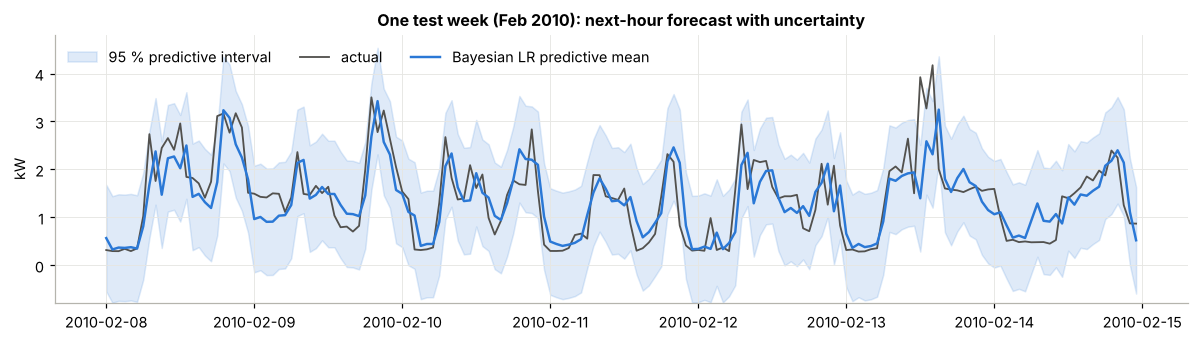

In [25]:
idx = test.index; mask = (idx >= '2010-02-08') & (idx < '2010-02-15')
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.fill_between(idx[mask], (mu_te - 1.96 * sd_te)[mask], (mu_te + 1.96 * sd_te)[mask], color=C[0], alpha=0.15, label='95 % predictive interval')
ax.plot(idx[mask], yte[mask], color='#52514e', lw=1.2, label='actual')
ax.plot(idx[mask], mu_te[mask], color=C[0], lw=1.6, label='Bayesian LR predictive mean')
ax.set_title('One test week (Feb 2010): next-hour forecast with uncertainty'); ax.set_ylabel('kW'); ax.legend(ncol=3, loc='upper left')
ax.set_ylim(bottom=min(0, ((mu_te - 1.96 * sd_te)[mask]).min()))
plt.tight_layout(); plt.show()

**Reading the forecast.** The predictive mean follows the daily rhythm and reacts within one hour to new peaks. It cannot anticipate a sudden spike (for example, an appliance switched on unexpectedly), and that error is the main reason for the remaining RMSE. One limitation shows here: the predictive variance is $1/\alpha + \boldsymbol\phi^\top S_N\boldsymbol\phi$, and with this much data the constant noise term $1/\alpha$ dominates. The interval is therefore almost the same width at 3 a.m. as at 8 p.m., so at night the band extends below 0 kW, which is physically impossible. A log-transformed target or a noise variance that depends on the hour would fix this.

### 2.3 When do ridge and the Bayesian prior help? Effect of training-set size
With 26 k training hours and only 37 features, the data overwhelm the prior, so OLS, ridge and Bayesian regression give nearly the same answer. To see the role of regularisation, we retrain on small random subsets ($n$ = 40 … 2000, 30 repeats each) and score on the same 2010 test set.

Median test RMSE (kW) over 30 random training subsets:
model  Bayesian LR    OLS  Ridge
n                               
40           0.625  1.308  0.606
60           0.605  0.838  0.594
100          0.596  0.684  0.595
200          0.558  0.573  0.558
500          0.530  0.529  0.530
2000         0.509  0.510  0.510


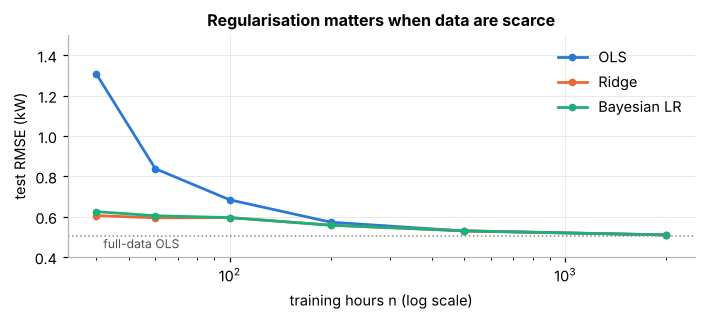

In [26]:
rng = np.random.default_rng(SEED); sizes = [40, 60, 100, 200, 500, 2000]; lc = []
lam_ridge = reg_models['Ridge (lambda by TS-CV)'].alpha_
for n in sizes:
    for r in range(30):
        i = rng.choice(len(Xtr_s), n, replace=False)
        for name, m in [('OLS', LinearRegression()), ('Ridge', Ridge(alpha=lam_ridge)), ('Bayesian LR', BayesianRidge())]:
            m.fit(Xtr_s[i], ytr.values[i]); lc.append((n, name, np.sqrt(mean_squared_error(yte, m.predict(Xte_s)))))
lc = pd.DataFrame(lc, columns=['n', 'model', 'RMSE']).groupby(['n', 'model'])['RMSE'].median().unstack()
print('Median test RMSE (kW) over 30 random training subsets:'); print(lc.round(3).to_string())

fig, ax = plt.subplots(figsize=(6.5, 3.0))
for k, mname in enumerate(['OLS', 'Ridge', 'Bayesian LR']): ax.plot(lc.index, lc[mname], marker='o', ms=4, color=C[k], label=mname)
ax.axhline(reg_table.loc['Least squares (OLS / MLE)', 'RMSE'], color='#8a8984', ls=':', lw=1)
ax.text(42, reg_table.loc['Least squares (OLS / MLE)', 'RMSE'] - 0.06, 'full-data OLS', fontsize=8, color='#52514e')
ax.set_xscale('log'); ax.set_ylim(0.4, 1.5); ax.set_xlabel('training hours n (log scale)'); ax.set_ylabel('test RMSE (kW)')
ax.set_title('Regularisation matters when data are scarce'); ax.legend(); plt.tight_layout(); plt.show()

## 2.4 Peak / off-peak label
$\text{peak}_t = 1$ if $y_t \ge \tau$ = **75th percentile of training-period hourly load** (same $\tau$ as Unit 1), so about 25 % of training hours are peak. The features are the same 37 lagged and calendar features. Because the classes are imbalanced, we report precision, recall, F1 and ROC-AUC as well as accuracy.

In [27]:
ctr = (ytr >= tau).astype(int).values; cte = (yte >= tau).astype(int).values
print(f'tau = {tau:.3f} kW | peak rate: train {ctr.mean():.3f}, test {cte.mean():.3f}')
clf_scores, clf_preds = {}, {}
def clf_metrics(y, pred, score):
    return {'Accuracy': accuracy_score(y, pred), 'Precision': precision_score(y, pred), 'Recall': recall_score(y, pred),
            'F1': f1_score(y, pred), 'ROC-AUC': roc_auc_score(y, score)}

tau = 1.596 kW | peak rate: train 0.249, test 0.224


## 2.5 Discriminant functions and probabilistic generative models
A **generative** classifier models $p(\mathbf x\mid C_k)$ and $p(C_k)$, then applies Bayes' rule to get $p(C_k\mid\mathbf x)$.
* **LDA:** Gaussian class-conditionals with a *shared* covariance matrix. The posterior is then $\sigma(\mathbf w^\top\mathbf x+w_0)$, so the discriminant function $y(\mathbf x)=\mathbf w^\top\mathbf x+w_0$ is **linear**.
* **Gaussian Naive Bayes:** assumes features are conditionally independent given the class (diagonal covariance).

In [28]:
for name, m in [('LDA (generative, shared cov.)', LinearDiscriminantAnalysis()), ('Gaussian Naive Bayes (generative)', GaussianNB())]:
    m.fit(Xtr_s, ctr); s = m.predict_proba(Xte_s)[:, 1]
    clf_preds[name] = (s, m.predict(Xte_s)); clf_scores[name] = clf_metrics(cte, m.predict(Xte_s), s)
pd.DataFrame(clf_scores).T.round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC
"LDA (generative, shared cov.)",0.8502,0.7677,0.4738,0.5860,0.9002
Gaussian Naive Bayes (generative),0.6963,0.4159,0.8843,0.5657,0.8506


## 2.6 Practice 2 — Bayesian logistic regression with the Laplace approximation (implemented from scratch)
**Discriminative model:** $p(C_1\mid\boldsymbol\phi)=\sigma(\mathbf w^\top\boldsymbol\phi)$ with prior $p(\mathbf w)=\mathcal N(\mathbf 0,\alpha^{-1}I)$.
1. **MAP weights** by Newton–Raphson (IRLS): gradient $\nabla E=\Phi^\top(\mathbf y-\mathbf t)+\alpha\mathbf w$, Hessian $\mathbf H=\Phi^\top R\,\Phi+\alpha I$ with $R=\mathrm{diag}(y_n(1-y_n))$.
2. **Laplace approximation:** posterior $q(\mathbf w)=\mathcal N(\mathbf w_{MAP},\,S_N)$ with $S_N=\mathbf H^{-1}$.
3. **Predictive distribution** (probit approximation): $p(C_1\mid\boldsymbol\phi)\approx\sigma\!\big(\kappa(\sigma_a^2)\,\mu_a\big)$, where $\mu_a=\mathbf w_{MAP}^\top\boldsymbol\phi$, $\sigma_a^2=\boldsymbol\phi^\top S_N\boldsymbol\phi$, $\kappa=(1+\pi\sigma_a^2/8)^{-1/2}$.
4. **Choosing α:** the Laplace approximation also gives the log model evidence, $\ln p(\mathcal D\mid\alpha)\approx\ln p(\mathcal D\mid\mathbf w_{MAP})+\ln p(\mathbf w_{MAP}\mid\alpha)+\tfrac M2\ln 2\pi-\tfrac12\ln|\mathbf H|$. We pick the α with the highest evidence.

In [29]:
class BayesianLogisticRegression:
    # Bayesian logistic regression: Gaussian prior N(0, 1/alpha I), Laplace approximation to the posterior
    def __init__(self, alpha=1.0, max_iter=100, tol=1e-8):
        self.alpha, self.max_iter, self.tol = alpha, max_iter, tol
    @staticmethod
    def _design(X): return np.hstack([np.ones((X.shape[0], 1)), X])
    def fit(self, X, t):
        Phi = self._design(X); w = np.zeros(Phi.shape[1]); A = self.alpha * np.eye(len(w))
        for it in range(self.max_iter):                       # Newton-Raphson / IRLS
            y = expit(Phi @ w)
            grad = Phi.T @ (y - t) + self.alpha * w
            Hess = (Phi * (y * (1 - y))[:, None]).T @ Phi + A
            step = np.linalg.solve(Hess, grad); w = w - step
            if np.linalg.norm(step) < self.tol: break
        y = expit(Phi @ w)
        self.H_ = (Phi * (y * (1 - y))[:, None]).T @ Phi + A
        self.w_map_, self.S_N_, self.n_iter_ = w, np.linalg.inv(self.H_), it + 1
        eps = 1e-12; M = len(w)
        loglik = np.sum(t * np.log(y + eps) + (1 - t) * np.log(1 - y + eps))
        logprior = 0.5 * M * np.log(self.alpha / (2 * np.pi)) - 0.5 * self.alpha * w @ w
        self.log_evidence_ = loglik + logprior + 0.5 * M * np.log(2 * np.pi) - 0.5 * np.linalg.slogdet(self.H_)[1]
        return self
    def predict_proba_map(self, X): return expit(self._design(X) @ self.w_map_)
    def predict_proba(self, X):                               # moderated (probit-approximated) predictive
        Phi = self._design(X); mu_a = Phi @ self.w_map_
        s2_a = np.einsum('ij,jk,ik->i', Phi, self.S_N_, Phi)
        return expit(mu_a / np.sqrt(1 + np.pi * s2_a / 8))
    def predict(self, X, thr=0.5): return (self.predict_proba(X) >= thr).astype(int)

alphas = [0.01, 0.1, 1, 10, 100, 1000]
ev = {a: BayesianLogisticRegression(alpha=a).fit(Xtr_s, ctr).log_evidence_ for a in alphas}
print('log evidence ln p(D | alpha):', {a: round(v, 1) for a, v in ev.items()})
alpha_best = max(ev, key=ev.get); print(f'-> alpha chosen by evidence = {alpha_best}')

blr = BayesianLogisticRegression(alpha=alpha_best).fit(Xtr_s, ctr)
print(f'Newton iterations: {blr.n_iter_}')
p_map, p_bayes = blr.predict_proba_map(Xte_s), blr.predict_proba(Xte_s)
s2 = np.einsum('ij,jk,ik->i', blr._design(Xte_s), blr.S_N_, blr._design(Xte_s))
print(f'posterior predictive variance sigma_a^2 on test: min {s2.min():.4f}, max {s2.max():.4f}; '
      f'max |p_MAP - p_moderated| = {np.abs(p_map - p_bayes).max():.4f}')

# check against scikit-learn's (non-Bayesian) L2 logistic regression with the same penalty
sk = LogisticRegression(C=1 / alpha_best, max_iter=5000, tol=1e-10).fit(Xtr_s, ctr)
print(f'max |w_MAP - sklearn w| = {np.abs(np.r_[sk.intercept_, sk.coef_.ravel()] - blr.w_map_).max():.2e}  '
      '(sanity check; the small gap is because our prior also covers the bias term, sklearn does not penalise it)')

clf_preds['Bayesian logistic regression (Laplace)'] = (p_bayes, blr.predict(Xte_s))
clf_scores['Bayesian logistic regression (Laplace)'] = clf_metrics(cte, blr.predict(Xte_s), p_bayes)

log evidence ln p(D | alpha): {0.01: np.float64(-8485.2), 0.1: np.float64(-8442.1), 1: np.float64(-8404.2), 10: np.float64(-8416.6), 100: np.float64(-8781.9), 1000: np.float64(-10422.9)}
-> alpha chosen by evidence = 1
Newton iterations: 8
posterior predictive variance sigma_a^2 on test: min 0.0061, max 0.0809; max |p_MAP - p_moderated| = 0.0034


max |w_MAP - sklearn w| = 1.75e-03  (sanity check; the small gap is because our prior also covers the bias term, sklearn does not penalise it)


**Where the Bayesian treatment changes predictions.** With 26 k training points the posterior is very narrow ($\sigma_a^2$ is small), so moderated and MAP probabilities almost coincide. With a **small** training set the posterior is wide and moderation pulls uncertain predictions towards 0.5. Below we train on 150 random hours (α fixed at 1) and compare probability quality with log-loss and Brier score (lower is better).

In [30]:
rng = np.random.default_rng(SEED); rows = []
for r in range(30):
    i = rng.choice(len(Xtr_s), 150, replace=False)
    if ctr[i].sum() < 5: continue
    m = BayesianLogisticRegression(alpha=1.0).fit(Xtr_s[i], ctr[i])
    pm, pb = np.clip(m.predict_proba_map(Xte_s), 1e-6, 1 - 1e-6), np.clip(m.predict_proba(Xte_s), 1e-6, 1 - 1e-6)
    rows.append({'log-loss MAP': log_loss(cte, pm), 'log-loss moderated': log_loss(cte, pb),
                 'Brier MAP': brier_score_loss(cte, pm), 'Brier moderated': brier_score_loss(cte, pb)})
small = pd.DataFrame(rows)
print(f'n = 150 training hours, {len(small)} repeats (mean):'); print(small.mean().round(4).to_string())
print(f'Moderated predictive has lower log-loss in {(small["log-loss moderated"] < small["log-loss MAP"]).mean()*100:.0f}% of repeats')

n = 150 training hours, 30 repeats (mean):
log-loss MAP          0.4831
log-loss moderated    0.4311
Brier MAP             0.1431
Brier moderated       0.1370
Moderated predictive has lower log-loss in 100% of repeats


## 2.7 Kernel functions, the kernel trick and SVM
A support vector machine (SVM) finds the maximum-margin separating boundary. Its dual form uses the data only through inner products $\mathbf x_n^\top\mathbf x_m$. Replacing them with a kernel $k(\mathbf x_n,\mathbf x_m)$ (the **kernel trick**) gives a linear boundary in an implicit feature space and a non-linear boundary in the input space.
* **Linear SVM:** $k(\mathbf x,\mathbf x')=\mathbf x^\top\mathbf x'$
* **RBF SVM:** $k(\mathbf x,\mathbf x')=\exp(-\gamma\lVert\mathbf x-\mathbf x'\rVert^2)$, with $\gamma$ = `'scale'`, $C = 1$

SVM scores are distances from the boundary, not probabilities; ROC-AUC uses these decision values.

In [31]:
for name, m in [('Linear SVM', LinearSVC(C=0.1, dual=False)), ('RBF-kernel SVM', SVC(kernel='rbf', C=1.0, gamma='scale'))]:
    t0 = time.time(); m.fit(Xtr_s, ctr); s = m.decision_function(Xte_s); pred = m.predict(Xte_s)
    clf_preds[name] = (s, pred); clf_scores[name] = clf_metrics(cte, pred, s)
    extra = f' | support vectors: {m.n_support_.sum():,} of {len(ctr):,}' if hasattr(m, 'n_support_') else ''
    print(f'{name}: trained in {time.time()-t0:.1f}s{extra}')

Linear SVM: trained in 0.2s


RBF-kernel SVM: trained in 20.0s | support vectors: 8,644 of 26,191


## 2.8 Classification comparison

In [32]:
order = ['Gaussian Naive Bayes (generative)', 'LDA (generative, shared cov.)', 'Bayesian logistic regression (Laplace)',
         'Linear SVM', 'RBF-kernel SVM']
clf_table = pd.DataFrame(clf_scores).T.loc[order]
clf_table.style.format('{:.4f}').highlight_max(axis=0, props='font-weight:bold; background-color:#e3eefb')

,Accuracy,Precision,Recall,F1,ROC-AUC
Gaussian Naive Bayes (generative),0.6963,0.4159,0.8843,0.5657,0.8506
"LDA (generative, shared cov.)",0.8502,0.7677,0.4738,0.5860,0.9002
Bayesian logistic regression (Laplace),0.8512,0.7547,0.4960,0.5986,0.9022
Linear SVM,0.8487,0.7662,0.4658,0.5794,0.9018
RBF-kernel SVM,0.8538,0.7520,0.5169,0.6127,0.8968


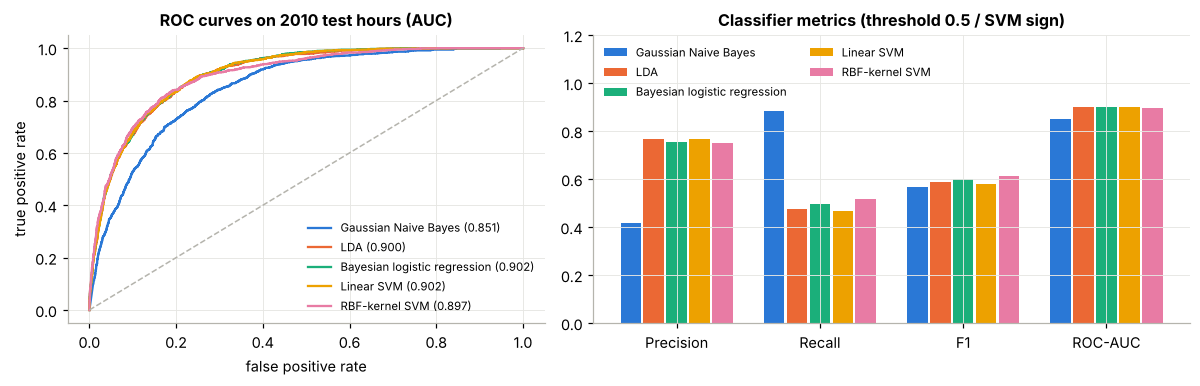

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={'width_ratios': [1, 1.25]})
for k, name in enumerate(order):
    fpr, tpr, _ = roc_curve(cte, clf_preds[name][0])
    axes[0].plot(fpr, tpr, color=C[k], lw=1.5, label=f'{name.split(" (")[0]} ({clf_scores[name]["ROC-AUC"]:.3f})')
axes[0].plot([0, 1], [0, 1], color='#b5b4ad', ls='--', lw=1)
axes[0].set_title('ROC curves on 2010 test hours (AUC)'); axes[0].set_xlabel('false positive rate'); axes[0].set_ylabel('true positive rate')
axes[0].legend(fontsize=7.5, loc='lower right')

mt = clf_table[['Precision', 'Recall', 'F1', 'ROC-AUC']]; xpos = np.arange(len(mt.columns)); wbar = 0.16
for k, name in enumerate(order):
    axes[1].bar(xpos + (k - 2) * wbar, mt.loc[name].values, width=wbar * 0.9, color=C[k], label=name.split(' (')[0])
axes[1].set_xticks(xpos); axes[1].set_xticklabels(mt.columns); axes[1].set_ylim(0, 1.2)
axes[1].set_title('Classifier metrics (threshold 0.5 / SVM sign)'); axes[1].legend(fontsize=7.5, ncol=2, loc='upper left')
plt.tight_layout(); plt.show()

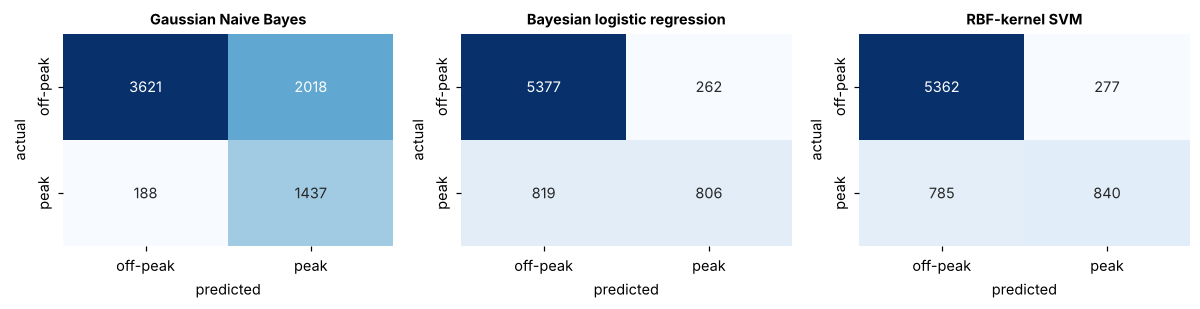

Bayesian LR — effect of the decision threshold on 2010 test hours:
  threshold 0.5: precision 0.755  recall 0.496  F1 0.599
  threshold 0.4: precision 0.703  recall 0.602  F1 0.649
  threshold 0.3: precision 0.633  recall 0.724  F1 0.676
  threshold 0.2: precision 0.536  recall 0.853  F1 0.658


In [34]:
fig, axes = plt.subplots(1, 3, figsize=(11, 2.9))
for ax, name in zip(axes, ['Gaussian Naive Bayes (generative)', 'Bayesian logistic regression (Laplace)', 'RBF-kernel SVM']):
    cm = confusion_matrix(cte, clf_preds[name][1])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax, xticklabels=['off-peak', 'peak'], yticklabels=['off-peak', 'peak'])
    ax.grid(False)
    ax.set_title(name.split(' (')[0], fontsize=9.5); ax.set_xlabel('predicted'); ax.set_ylabel('actual')
plt.tight_layout(); plt.show()

# precision / recall trade-off for the Bayesian logistic model
print('Bayesian LR — effect of the decision threshold on 2010 test hours:')
for thr in [0.5, 0.4, 0.3, 0.2]:
    pr = (p_bayes >= thr).astype(int)
    print(f'  threshold {thr:.1f}: precision {precision_score(cte, pr):.3f}  recall {recall_score(cte, pr):.3f}  F1 {f1_score(cte, pr):.3f}')

## 2.9 Comparative performance analysis

In [35]:
print('REGRESSION — next-hour Global_active_power, test = 2010')
print(reg_table[['RMSE', 'MAE', 'R2']].round(4).to_string())
print('\nCLASSIFICATION — peak / off-peak hour, test = 2010')
print(clf_table.round(4).to_string())

REGRESSION — next-hour Global_active_power, test = 2010
                              RMSE     MAE      R2
Persistence (y[t-1])        0.6180  0.4070  0.3706
Seasonal naive (y[t-24])    0.8217  0.5562 -0.1129
Least squares (OLS / MLE)   0.5043  0.3624  0.5808
Huber (robust)              0.5080  0.3527  0.5747
Ridge (lambda by TS-CV)     0.5042  0.3622  0.5810
Bayesian linear regression  0.5043  0.3624  0.5809

CLASSIFICATION — peak / off-peak hour, test = 2010
                                        Accuracy  Precision  Recall      F1  ROC-AUC
Gaussian Naive Bayes (generative)         0.6963     0.4159  0.8843  0.5657   0.8506
LDA (generative, shared cov.)             0.8502     0.7677  0.4738  0.5860   0.9002
Bayesian logistic regression (Laplace)    0.8512     0.7547  0.4960  0.5986   0.9022
Linear SVM                                0.8487     0.7662  0.4658  0.5794   0.9018
RBF-kernel SVM                            0.8538     0.7520  0.5169  0.6127   0.8968


## 2.10 Interpretation of results

**Regression (next-hour active power, test year 2010).**
* All four linear models beat the persistence baseline: **RMSE 0.504 vs 0.618 kW (−18.4 %)**, and R² rises from 0.37 to **0.58**. Repeating yesterday's value (seasonal naive) is worse than predicting the mean (R² −0.11), because day-to-day routines vary a lot in this house.
* **OLS, ridge and Bayesian linear regression are practically identical on the full data** (RMSE 0.5042–0.5043). With 26,191 training hours and 37 features the likelihood dominates the prior: the ridge penalty chosen by time-series CV (λ = 38.6) shrinks coefficients by only about 1 %. The training-size experiment (2.3) shows where regularisation matters: at **n = 40, OLS has test RMSE 1.31 while ridge has 0.61 and Bayesian 0.63**. By n ≥ 500 all three agree.
* **Huber (robust) regression has the best MAE (0.353 vs 0.362) but a slightly worse RMSE (0.508).** It down-weights large surprise spikes, so typical hours are predicted better and the rare big spikes worse. This also tells us the residuals are heavy-tailed.
* **The Bayesian model's uncertainty is useful but imperfect.** The 95 % interval covers 96.0 % of test hours, but the 68 % interval covers 79.3 %. Errors are mostly small with a few large spikes, which is not Gaussian. The interval also extends below 0 kW at night (see 2.2).
* The largest weight is on the previous hour's load (0.78 standardised), followed by the 07 h and 18–20 h indicators: the model has learned the daily rhythm seen in Unit 1.

**Classification (peak vs off-peak hour, test year 2010).**
* **Bayesian logistic regression and linear SVM have the highest ROC-AUC (0.902)**, with LDA close behind (0.900). The **RBF-kernel SVM has the best accuracy (0.854) and F1 (0.613)** at the default threshold, but a slightly *lower* AUC (0.897). It takes 20 s and keeps 8,644 support vectors (33 % of the training set), against 0.2 s for the linear SVM. The kernel trick adds little here, which means the peak / off-peak boundary is close to linear in these features.
* **Generative vs discriminative.** LDA, which is generative with a shared covariance and so has a linear discriminant, almost matches discriminative logistic regression. **Gaussian Naive Bayes is clearly worst (AUC 0.851)**: its assumption that features are independent given the class is badly violated (lag-1, lag-2, lag-3 and the 24-h mean are strongly correlated). It counts the same evidence several times, becomes over-confident towards "peak", and reaches recall 0.88 with precision only 0.42.
* **Laplace approximation.** The evidence picks α = 1. On the full data, moderated and MAP probabilities differ by at most 0.003 because the posterior is very narrow. With only 150 training hours, the moderated predictive **lowers log-loss from 0.483 to 0.431 and was better in 30 of 30 repeats**. This is the same lesson as regression: the Bayesian treatment matters most when data are scarce.
* **The threshold matters as much as the model.** At 0.5, the linear models catch only about half of the peak hours (recall ≈ 0.50). Lowering the Bayesian LR threshold to 0.3 raises recall to 0.72 at precision 0.63, giving F1 0.676, higher than any model at 0.5. In practice the threshold should be set from the relative cost of a missed peak vs a false alarm, using a validation period rather than the test year.

## Conclusions
* **Objective met.** Unit 1 characterised the household's consumption with probability: a bimodal, right-skewed power distribution; near-Gaussian voltage; two daily peaks; P(peak | evening) = 0.47 vs a prior of 0.245; peak load depends on weekend; kitchen and laundry use are not conditionally independent given time of day. Unit 2 built and compared every model in the syllabus mapping on a leak-free, chronological set-up.
* **Best models.** Regression: ridge / Bayesian linear regression (RMSE 0.504 kW, R² 0.58), with the Bayesian model also giving a 95 % interval that is well calibrated overall. Classification: Bayesian logistic regression for ranking peak hours (AUC 0.902, with calibrated probabilities and the cheapest training cost); RBF SVM for the best F1 at the default threshold (0.613).
* **Main lessons.** (1) Remove variables that leak the target. (2) Regularisation and Bayesian priors matter when data are scarce and have little effect with 26 k samples. (3) A model's assumptions show in its errors: Gaussian noise gives negative-power intervals, and the naive independence assumption gives over-confident Naive Bayes.
* **Limitations.** One household only, so results describe this home and not households in general. Only hourly lags and calendar features were used (no weather data). The 2010 test year has fewer peak hours (22.4 %) than training (24.9 %).
* **Next units.** Unit 3 will cluster the 1,419 complete daily load curves (K-means, GMM, hierarchical, PCA). Unit 4 will model the hidden occupancy / load state found in 1.9 with an HMM. Unit 5 will compare tree ensembles with the Unit 2 classifiers on the same peak label and test year.